In [ ]:
# Import necessary libraries
import pandas as pd

In [ ]:
# Read the CSV files into DataFrames
df = pd.read_csv("../data/landing/transactions_2026-09-01.csv",
                 dtype=str, keep_default_na=False)
accounts = pd.read_csv("../data/landing/reference/accounts.csv", dtype=str)

In [ ]:
# Number of rows and columns in the transactions DataFrame
df.shape

(2046, 8)

In [ ]:
# Display the first few rows of the transactions DataFrame
df.head()

,transaction_id,account_id,counterparty_account_id,amount,currency,transaction_type,country,transaction_timestamp
0,T20260901001934,A0000535,X9965561,12.79,EUR,card_payment,ES,2026-09-01 08:16:47
1,T20260901001269,A0001355,X5528347,27.47,GBP,card_payment,GB,2026-09-01 14:24:47
2,T20260901001865,A0000634,X2696224,75.97,EUR,transfer,FR,2026-09-01 22:43:06
3,T20260901000356,A0001209,X9135937,37.12,USD,transfer,US,2026-09-01 20:14:22
4,T20260901000008,A0001110,X1542215,23.42,EUR,direct_debit,DE,2026-09-01 09:45:03


In [ ]:
# Complétude et doublons
print((df == "").sum())                                   # champs vides par colonne
print("Doublons exacts :", df.duplicated().sum())
ids = df.loc[df["transaction_id"] != "", "transaction_id"]
print("Identifiants répétés :", ids.duplicated().sum())

transaction_id             20
account_id                  0
counterparty_account_id     0
amount                      0
currency                    0
transaction_type            0
country                     0
transaction_timestamp       0
dtype: int64
Doublons exacts : 20
Identifiants répétés : 20


In [ ]:
# Conversion des types
amount = pd.to_numeric(df["amount"], errors="coerce")
ts = pd.to_datetime(df["transaction_timestamp"], format="%Y-%m-%d %H:%M:%S", errors="coerce")

print("Montants non numériques :", amount.isna().sum())
print("Montants <= 0 :", (amount <= 0).sum())
print("Dates invalides :", ts.isna().sum())
df[ts.isna()].head()

Montants non numériques : 0
Montants <= 0 : 20
Dates invalides : 20


,transaction_id,account_id,counterparty_account_id,amount,currency,transaction_type,country,transaction_timestamp
49,T20260901001055,A0000484,X4728340,41.33,EUR,card_payment,IT,2026-13-45 25:61:00
102,T20260901001043,A0000137,X0768815,33.89,EUR,card_payment,FR,2026-13-45 25:61:00
154,T20260901000575,A0000917,X8169375,140.78,EUR,transfer,IT,2026-13-45 25:61:00
410,T20260901001038,A0000001,X2597920,31.29,EUR,card_payment,FR,2026-13-45 25:61:00
451,T20260901001425,A0001049,X7763326,61.18,EUR,transfer,IT,2026-13-45 25:61:00


In [ ]:
# Domaines de valeurs et intégrité référentielle
for col in ["currency", "transaction_type", "country"]:
    print(df[col].value_counts(), "\n")

orphans = ~df["account_id"].isin(accounts["account_id"])
print("Comptes inexistants :", orphans.sum())

currency
EUR    1838
GBP      98
USD      90
ZZZ      20
Name: count, dtype: int64 

transaction_type
card_payment    1250
transfer         384
withdrawal       211
direct_debit     201
Name: count, dtype: int64 

country
FR    988
IT    236
DE    222
BE    208
ES    197
GB    101
US     94
Name: count, dtype: int64 

Comptes inexistants : 20


count    2046.000000
mean       44.428519
std        45.828673
min      -144.450000
50%        34.185000
90%        85.790000
99%       183.177500
99.9%     419.091800
max      1168.590000
Name: amount, dtype: float64


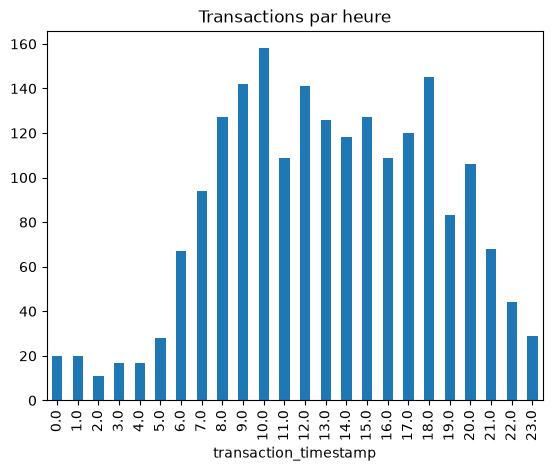

In [8]:
# Distributions
print(amount.describe(percentiles=[.5, .9, .99, .999]))
ts.dt.hour.value_counts().sort_index().plot(kind="bar", title="Transactions par heure");

In [9]:
# Validation contre la vérité terrain
truth = pd.read_csv("../data/ground_truth/defects_2026-09-01.csv")
print(truth["defect_type"].value_counts())

defect_type
missing_id             20
non_positive_amount    20
unknown_currency       20
unknown_account        20
invalid_timestamp      20
duplicate              20
Name: count, dtype: int64
